# ERA5 850 hPa 風場與 MSE：南美洲（1990–2019）

讀取 `SAm_data/` 裡已切成南美洲範圍（100°W–25°W、60°S–20°N）的 1990–2019 日資料（由 `SAm_data/prep_SAm_1990-2019.sh` 產生，每檔約 0.8 GB），計算全期與 DJF/JJA 平均，用 cartopy 畫 MSE 填色＋風向量。

In [6]:
import os, sys
# 讓 PROJ 找得到資料庫（未 activate conda 環境時也能用）
os.environ.setdefault('PROJ_DATA', os.path.join(sys.prefix, 'share', 'proj'))
os.environ.setdefault('PROJ_LIB', os.environ['PROJ_DATA'])

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DATA_DIR = '../SAm_data'   # 南美洲 1990–2019（舊的全球檔在 ../wind_data、../mse_data）
PERIOD = '1990-2019'
FIG_DIR = '../Figures'
os.makedirs(FIG_DIR, exist_ok=True)

import matplotlib.ticker as mticker
# 畫圖範圍：南美洲 [lon_min, lon_max, lat_min, lat_max]（°E，負值為西經）
EXTENT = [-95, -30, -55, 15]
REGION = 'SAm'   # 輸出檔名後綴

In [7]:
# lazy 讀取：只建立 dask 陣列
chunks = {'time': 366}
u = xr.open_dataset(f'{DATA_DIR}/u850_{REGION}_{PERIOD}.nc', chunks=chunks)['u']
v = xr.open_dataset(f'{DATA_DIR}/v850_{REGION}_{PERIOD}.nc', chunks=chunks)['v']
print(u)
print('time steps:', u.sizes['time'], '|', str(u.time.values[0])[:10], '→', str(u.time.values[-1])[:10])

<xarray.DataArray 'u' (time: 10957, lat: 160, lon: 120)> Size: 841MB
dask.array<open_dataset-u, shape=(10957, 160, 120), dtype=float32, chunksize=(366, 160, 120), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 88kB 1990-01-01 1990-01-02 ... 2019-12-31
  * lon      (lon) float32 480B 260.3 260.9 261.6 262.2 ... 333.4 334.1 334.7
  * lat      (lat) float32 640B -59.75 -59.25 -58.75 ... 18.75 19.25 19.75
Attributes:
    standard_name:  eastward_wind
    long_name:      U component of wind
    units:          m s**-1
time steps: 10957 | 1990-01-01 → 2019-12-31


In [8]:
# 長期平均與季節平均（DJF / JJA），只把 2D 結果載入記憶體
u_mean = u.mean('time').compute()
v_mean = v.mean('time').compute()

u_seas = u.groupby('time.season').mean('time').compute()
v_seas = v.groupby('time.season').mean('time').compute()
print(u_mean.shape, list(u_seas.season.values))

(160, 120) ['DJF', 'JJA', 'MAM', 'SON']


### 讀取 850 hPa MSE（當作風場圖的底色）

`SAm_data/mse850_SAm_1990-2019.nc`：MSE = Cp·T + Φ + Lv·q，單位 J/kg，這裡換成 kJ/kg。

In [9]:
mse = xr.open_dataset(f'{DATA_DIR}/mse850_{REGION}_{PERIOD}.nc', chunks={'time': 366})['mse']
print(mse)

mse_mean = (mse.mean('time') / 1000).compute()                         # kJ/kg
mse_seas = (mse.groupby('time.season').mean('time') / 1000).compute()
print('mean range: %.1f – %.1f kJ/kg' % (float(mse_mean.min()), float(mse_mean.max())))

<xarray.DataArray 'mse' (time: 10957, lat: 160, lon: 120)> Size: 841MB
dask.array<open_dataset-mse, shape=(10957, 160, 120), dtype=float32, chunksize=(366, 160, 120), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 88kB 1990-01-01T11:30:00 ... 2019-12-31T11...
  * lon      (lon) float32 480B 260.3 260.9 261.6 262.2 ... 333.4 334.1 334.7
  * lat      (lat) float32 640B -59.75 -59.25 -58.75 ... 18.75 19.25 19.75
Attributes:
    units:      J kg-1
    long_name:  Moist static energy at 850 hPa (Cp*T + Phi + Lv*q)
mean range: 281.2 – 341.6 kJ/kg


In [10]:
def plot_wind(uu, vv, shade, title, fname, skip=6, levels=np.arange(280, 352, 2)):
    """MSE 填色（kJ/kg）+ 風向量（每 skip 個格點畫一支箭頭），範圍由 EXTENT 決定"""
    lon, lat = uu.lon.values, uu.lat.values

    fig = plt.figure(figsize=(8, 9))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    cf = ax.contourf(lon, lat, shade.values, levels=levels, cmap='RdYlBu_r',
                     extend='both', transform=ccrs.PlateCarree())
    q = ax.quiver(lon[::skip], lat[::skip], uu.values[::skip, ::skip], vv.values[::skip, ::skip],
                  transform=ccrs.PlateCarree(), scale=150, width=0.003, color='k', regrid_shape=None)
    ax.quiverkey(q, 0.86, 1.03, 10, '10 m/s', labelpos='E', coordinates='axes')
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4, edgecolor='gray')
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', linestyle='--')
    gl.xlocator = mticker.FixedLocator(range(-90, -29, 10))
    gl.ylocator = mticker.FixedLocator(range(-50, 16, 10))
    gl.top_labels = gl.right_labels = False
    cb = plt.colorbar(cf, ax=ax, orientation='horizontal', pad=0.06, shrink=0.9)
    cb.set_label('850 hPa moist static energy (kJ/kg)')
    ax.set_title(title, fontsize=12, loc='left')
    fig.savefig(f'{FIG_DIR}/{fname}', dpi=150, bbox_inches='tight')
    plt.show()

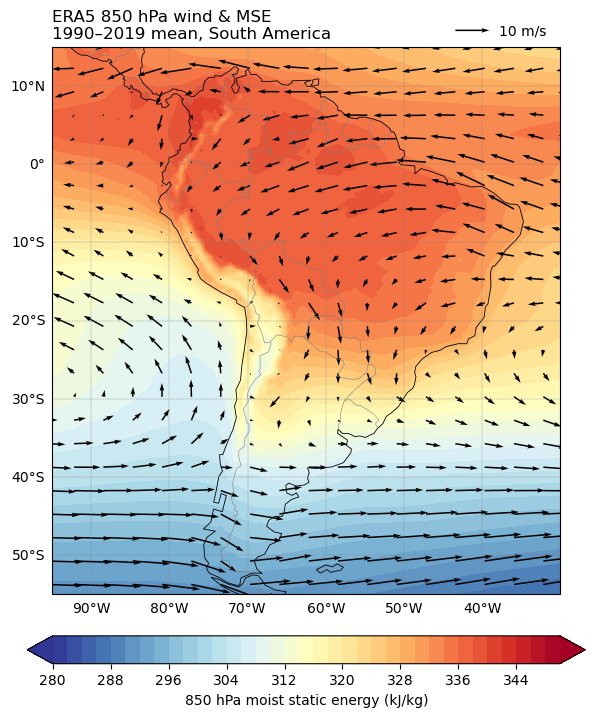

In [11]:
plot_wind(u_mean, v_mean, mse_mean, 'ERA5 850 hPa wind & MSE\n1990–2019 mean, South America', f'uv850_mse_mean_{PERIOD}_{REGION}.png')

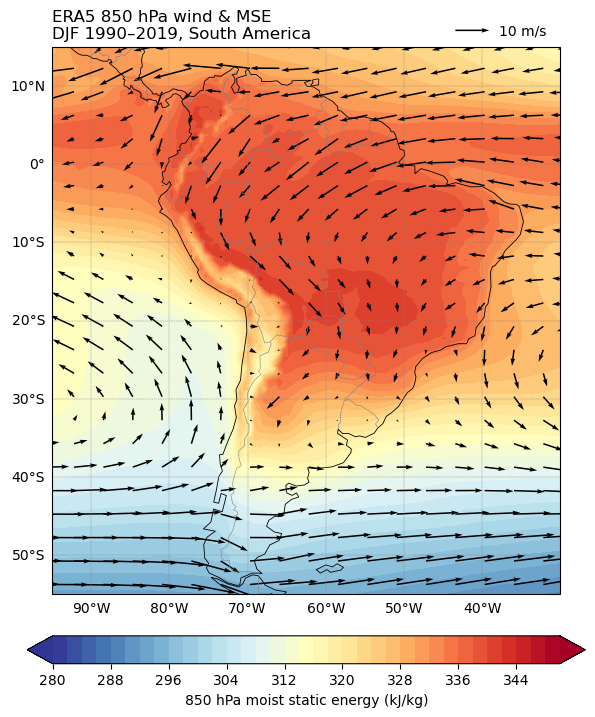

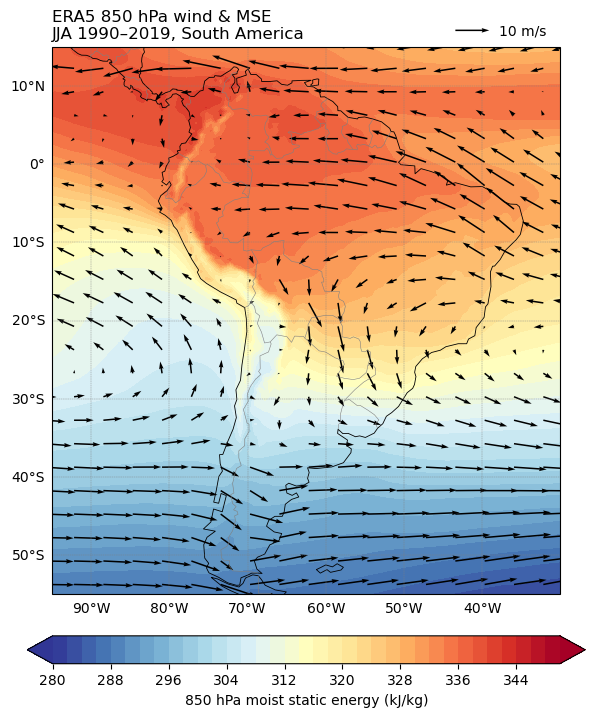

In [12]:
for s in ['DJF', 'JJA']:
    plot_wind(u_seas.sel(season=s), v_seas.sel(season=s), mse_seas.sel(season=s),
              f'ERA5 850 hPa wind & MSE\n{s} 1990–2019, South America', f'uv850_mse_{s}_{PERIOD}_{REGION}.png')

## 只畫 850 hPa MSE（南美洲，1990–2019）

單獨的 MSE contourf 圖（不含風場）。

注意：青藏高原、南極、格陵蘭等地 850 hPa 在地表以下，該處數值為 ERA5 外插值。

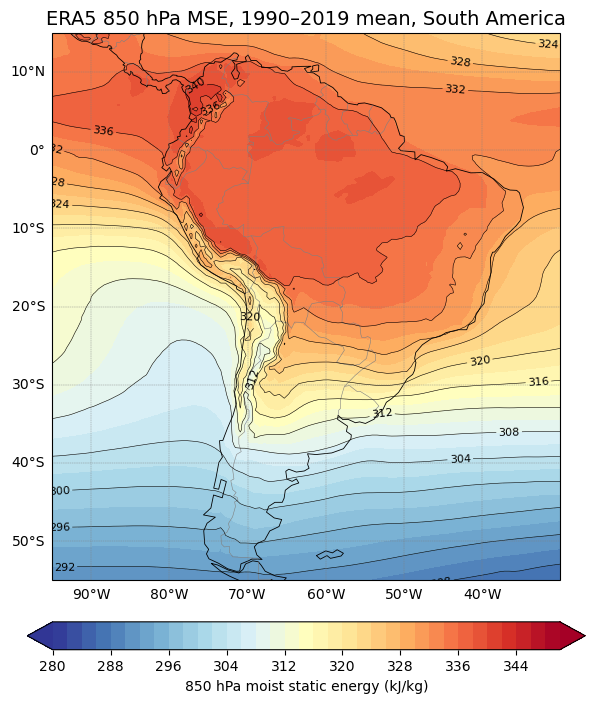

In [13]:
def plot_mse(field, title, fname, levels=np.arange(280, 352, 2)):
    """MSE 填色（kJ/kg）+ 等值線"""
    lon, lat = field.lon.values, field.lat.values
    data = field.values

    fig = plt.figure(figsize=(8, 9))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    cf = ax.contourf(lon, lat, data, levels=levels, cmap='RdYlBu_r',
                     extend='both', transform=ccrs.PlateCarree())
    cs = ax.contour(lon, lat, data, levels=levels[::2], colors='k',
                    linewidths=0.4, transform=ccrs.PlateCarree())
    ax.clabel(cs, fmt='%d', fontsize=8)
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4, edgecolor='gray')
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', linestyle='--')
    gl.xlocator = mticker.FixedLocator(range(-90, -29, 10))
    gl.ylocator = mticker.FixedLocator(range(-50, 16, 10))
    gl.top_labels = gl.right_labels = False
    cb = plt.colorbar(cf, ax=ax, orientation='horizontal', pad=0.06, shrink=0.9)
    cb.set_label('850 hPa moist static energy (kJ/kg)')
    ax.set_title(title, fontsize=14)
    fig.savefig(f'{FIG_DIR}/{fname}', dpi=150, bbox_inches='tight')
    plt.show()

plot_mse(mse_mean, 'ERA5 850 hPa MSE, 1990–2019 mean, South America', f'mse850_mean_{PERIOD}_{REGION}.png')

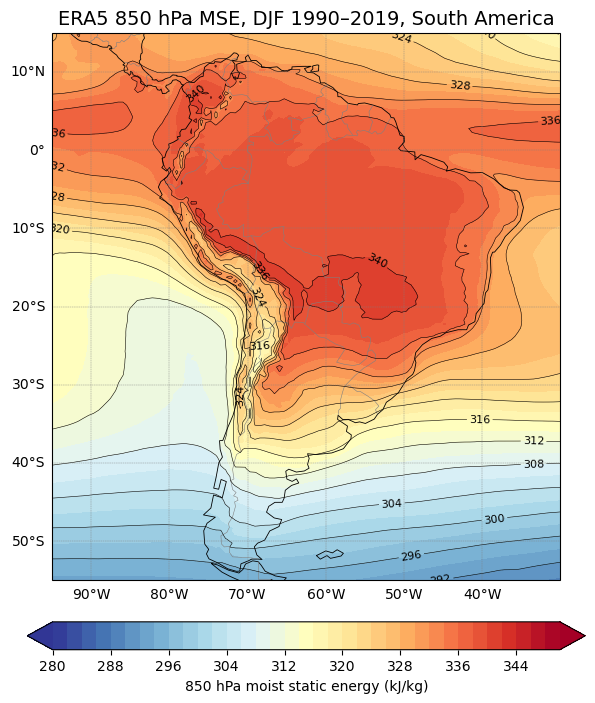

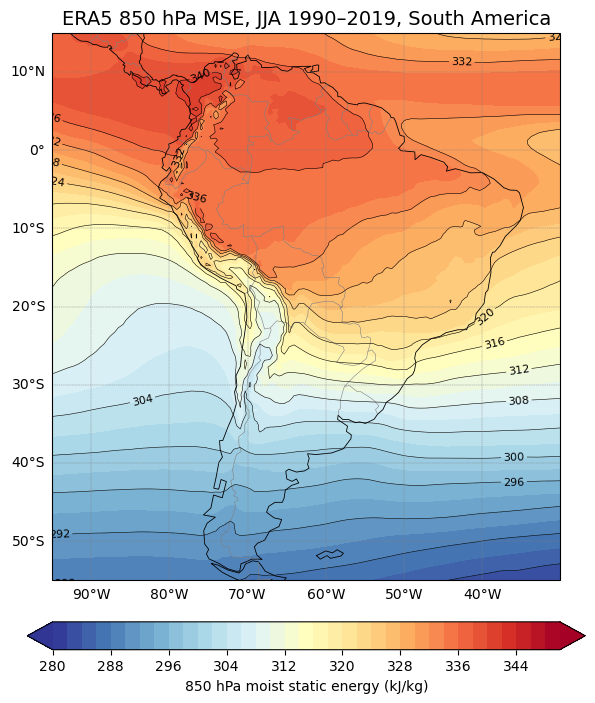

In [14]:
for s in ['DJF', 'JJA']:
    plot_mse(mse_seas.sel(season=s), f'ERA5 850 hPa MSE, {s} 1990–2019, South America', f'mse850_{s}_{PERIOD}_{REGION}.png')